# **Assignment 1 - Applied Data Science**
~ Kevin Tjahjadi ~
========================================


Importing important libraries and reading the dataset

In [488]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path

In [489]:
df = pd.read_csv("2.Raw_cafe_sales Assignment 1.csv")
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2,4,Credit Card,Takeaway,8/9/2023
1,TXN_4977031,Cake,4,3,12,Cash,In-store,16/5/2023
2,TXN_4271903,Cookie,4,1,ERROR,Credit Card,In-store,19/7/2023
3,TXN_7034554,Salad,2,5,10,UNKNOWN,UNKNOWN,27/4/2023
4,TXN_3160411,Coffee,2,2,4,Digital Wallet,In-store,11/6/2023


# **Data Preprocessing & EDA**



---



### **Clean and prepare the assigned dataset**



---







Data auditing to check the structure of the data

In [490]:
def create_audit(df):
  """
    Create an audit to see what the data is looking like right now
    (Type, Amount of Missing Values, Amount of Unique Values)
  """
  audit = pd.DataFrame({
      "dtype": df.dtypes,
      "n_missing": df.isnull().sum(),
      "pct_missing": round(df.isnull().mean() * 100, 2),
      "n_unique": df.nunique()
  })
  return audit

create_audit(df)

,dtype,n_missing,pct_missing,n_unique
Transaction ID,object,0,0.00,10000
Item,object,333,3.33,10
Quantity,object,138,1.38,7
Price Per Unit,object,179,1.79,8
Total Spent,object,173,1.73,19
Payment Method,object,2579,25.79,5
Location,object,3265,32.65,4
Transaction Date,object,159,1.59,367


In [491]:
data = df.copy()

There are "ERROR" and "UNKNOWN", because we don't know the value, we replace them as missing

In [492]:
data = data.replace(["ERROR", "UNKNOWN"], np.nan)

All of the types are object, so we have to change it to either numeric or datetime based on their type

In [493]:
numeric = ["Quantity", "Price Per Unit", "Total Spent"]
date = ["Transaction Date"]

for column in numeric:
  data[column] = pd.to_numeric(data[column])
for column in date:
  data[column] = pd.to_datetime(data[column], format="%d/%m/%Y")

In [494]:
create_audit(data)

,dtype,n_missing,pct_missing,n_unique
Transaction ID,object,0,0.00,10000
Item,object,969,9.69,8
Quantity,float64,479,4.79,5
Price Per Unit,float64,533,5.33,6
Total Spent,float64,502,5.02,17
Payment Method,object,3178,31.78,3
Location,object,3961,39.61,2
Transaction Date,datetime64[ns],460,4.60,365


### Filling missing values


Filling some columns logically:
- "Price Per Unit" can be filled by looking at the other item with the same name (by mapping)

In [495]:
known = data.dropna(subset=["Item", "Price Per Unit"])
price_map = (
    data.groupby("Item")["Price Per Unit"]
    .agg(lambda s: s.mode()[0])
    .to_dict()
)
price_map

{'Cake': 3.0,
 'Coffee': 2.0,
 'Cookie': 1.0,
 'Juice': 3.0,
 'Salad': 5.0,
 'Sandwich': 4.0,
 'Smoothie': 4.0,
 'Tea': 1.5}

In [496]:
data["Price Per Unit"] = data["Price Per Unit"].fillna(df["Item"].map(price_map))

- "Quantity" can be filled by calculating Total Spent / Price Per Unit (Also change "Quantity" to Integer, because it's discrete)

In [497]:
missing_q = data["Quantity"].isna() & data["Total Spent"].notna() & data["Price Per Unit"].notna()
if missing_q.any():
  data.loc[missing_q, "Quantity"] = data.loc[missing_q, "Total Spent"] / data.loc[missing_q, "Price Per Unit"]

data["Quantity"] = data["Quantity"].astype("Int64")

- "Total Spent" can be filled by calculating Quantity * Price Per Unit

In [498]:
missing_t = data["Total Spent"].isna() & data["Quantity"].notna() & data["Price Per Unit"].notna()
if missing_t.any():
  data.loc[missing_t, "Total Spent"] = data.loc[missing_t, "Quantity"] * data.loc[missing_t, "Price Per Unit"]

In [499]:
create_audit(data)

,dtype,n_missing,pct_missing,n_unique
Transaction ID,object,0,0.00,10000
Item,object,969,9.69,8
Quantity,Int64,23,0.23,5
Price Per Unit,float64,54,0.54,6
Total Spent,float64,23,0.23,17
Payment Method,object,3178,31.78,3
Location,object,3961,39.61,2
Transaction Date,datetime64[ns],460,4.60,365


In [500]:
data[data["Price Per Unit"].isna()]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
118,TXN_4633784,NaN,5,NaN,15.0,NaN,In-store,2023-02-06
151,TXN_4031509,NaN,4,NaN,16.0,Credit Card,Takeaway,2023-01-04
289,TXN_3495950,NaN,4,NaN,6.0,Credit Card,In-store,2023-02-19
334,TXN_2523298,NaN,4,NaN,6.0,NaN,In-store,2023-03-25
550,TXN_4186681,NaN,4,NaN,6.0,Digital Wallet,NaN,2023-05-24
750,TXN_5787508,NaN,3,NaN,9.0,Credit Card,Takeaway,2023-07-23
818,TXN_7940202,NaN,1,NaN,4.0,Digital Wallet,NaN,2023-07-23
1154,TXN_2473090,NaN,2,NaN,3.0,Credit Card,In-store,2023-03-03
1337,TXN_5031214,NaN,5,NaN,5.0,NaN,Takeaway,2023-07-29
1377,TXN_8396271,NaN,2,NaN,2.0,NaN,NaN,2023-09-12


- Some "Price Per Unit" with no "Item" still missing but with "Quantity" and "Total Spent" filled, so we can do the same to it.

In [501]:
missing_p = data["Price Per Unit"].isna() & data["Total Spent"].notna() & data["Quantity"].notna()
if missing_p.any():
  data.loc[missing_p, "Price Per Unit"] = data.loc[missing_p, "Total Spent"] / data.loc[missing_p, "Quantity"]

- Otherwise, fill with median

In [502]:
for column in numeric:
  data[column] = data[column].fillna(data[column].median())

In [503]:
create_audit(data)

,dtype,n_missing,pct_missing,n_unique
Transaction ID,object,0,0.00,10000
Item,object,969,9.69,8
Quantity,Int64,0,0.00,5
Price Per Unit,float64,0,0.00,6
Total Spent,float64,0,0.00,17
Payment Method,object,3178,31.78,3
Location,object,3961,39.61,2
Transaction Date,datetime64[ns],460,4.60,365


- Item from price (only unambiguous prices, \$3 and \$4 are shared by two items)

In [504]:
items_by_price = {}
for item, price in price_map.items():
    items_by_price.setdefault(price, []).append(item)
unique_price = {p: i[0] for p, i in items_by_price.items() if len(i) == 1}
no_item = data["Item"].isna()
data.loc[no_item, "Item"] = data.loc[no_item, "Price Per Unit"].map(unique_price)

In [505]:
create_audit(data)

,dtype,n_missing,pct_missing,n_unique
Transaction ID,object,0,0.00,10000
Item,object,480,4.80,8
Quantity,Int64,0,0.00,5
Price Per Unit,float64,0,0.00,6
Total Spent,float64,0,0.00,17
Payment Method,object,3178,31.78,3
Location,object,3961,39.61,2
Transaction Date,datetime64[ns],460,4.60,365


Some items still have missing values.


---



Filling columns with no information:

- Because we don't know what to fill the missing values from "Item", "Payment Method", and "Location", so we just fill them with "Unknown"

In [506]:
data[["Payment Method", "Location", "Item"]] = (
    data[["Payment Method", "Location", "Item"]].fillna("Unknown")
)

Making "Transaction Date" into meaningful information:
- We can add columns to make the Transaction Date become more meaningful (Month, Day, Quarter)

In [507]:
data["Month"] = data["Transaction Date"].dt.month.astype("Int64")
data["Day"] = data["Transaction Date"].dt.day_name()
data["Quarter"] = data["Transaction Date"].dt.quarter.astype("Int64")

In [508]:
data.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Month,Day,Quarter
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08,9,Friday,3
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16,5,Tuesday,2
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-store,2023-07-19,7,Wednesday,3
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,Unknown,2023-04-27,4,Thursday,2
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11,6,Sunday,2


In [509]:
create_audit(data)

,dtype,n_missing,pct_missing,n_unique
Transaction ID,object,0,0.0,10000
Item,object,0,0.0,9
Quantity,Int64,0,0.0,5
Price Per Unit,float64,0,0.0,6
Total Spent,float64,0,0.0,17
Payment Method,object,0,0.0,4
Location,object,0,0.0,3
Transaction Date,datetime64[ns],460,4.6,365
Month,Int64,460,4.6,12
Day,object,460,4.6,7




---



### **Compute descriptive statistics**



---



Looking at the shape of the dataset and duplicated values

In [510]:
print("Shape of dataset:", data.shape)
print("Number of duplicate rows:", data.duplicated().sum())

Shape of dataset: (10000, 11)
Number of duplicate rows: 0


No duplicated rows



---


Since we can't get any information from an unknown item for item-level analysis, we don't take the unknown item for analysis

In [511]:
data = data[data["Item"] != "Unknown"]

Now we can do the summary statistics

In [512]:
numeric_data = data[numeric]
descriptive_stats = numeric_data.describe().T
descriptive_stats["median"] = numeric_data.median()
descriptive_stats["mode"] = numeric_data.mode().iloc[0]
descriptive_stats["skew"] = numeric_data.skew()

print("Numeric summary:")
display(descriptive_stats)

Numeric summary:


,count,mean,std,min,25%,50%,75%,max,median,mode,skew
Quantity,9520.0,3.021954,1.420381,1.0,2.0,3.0,4.0,5.0,3.0,5.0,-0.003077
Price Per Unit,9520.0,2.920536,1.301071,1.0,1.5,3.0,4.0,5.0,3.0,3.0,0.056321
Total Spent,9520.0,8.835609,6.02201,1.0,4.0,7.5,12.0,25.0,7.5,6.0,0.858005


From the numeric summary, we can see that:
- "Quantity" and "Price Per Unit" only ranges from 1 to 5.
- "Total Spent" never exceeds 5 x \$5 = \$25.


---
Checking outliers using IQR Rule:


In [513]:
total_spent = numeric_data["Total Spent"]
q1, q3 = total_spent.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = (total_spent < lower_bound) | (total_spent > upper_bound)
print("Lower Bound: ", lower_bound)
print("Upper Bound: ", upper_bound)
print("Outliers:")
display(data[outliers])

Lower Bound:  -8.0
Upper Bound:  24.0
Outliers:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Month,Day,Quarter
10,TXN_2548360,Salad,5,5.0,25.0,Cash,Takeaway,2023-11-07,11,Tuesday,4
51,TXN_6342161,Salad,5,5.0,25.0,Unknown,Takeaway,2023-01-08,1,Sunday,1
52,TXN_8914892,Salad,5,5.0,25.0,Digital Wallet,Unknown,2023-03-15,3,Wednesday,1
96,TXN_5220895,Salad,5,5.0,25.0,Cash,In-store,2023-06-10,6,Saturday,2
100,TXN_9517146,Salad,5,5.0,25.0,Cash,Takeaway,2023-10-30,10,Monday,4
...,...,...,...,...,...,...,...,...,...,...,...
9791,TXN_1232346,Salad,5,5.0,25.0,Digital Wallet,In-store,2023-01-04,1,Wednesday,1
9805,TXN_9506076,Salad,5,5.0,25.0,Unknown,Unknown,2023-01-17,1,Tuesday,1
9879,TXN_6393305,Salad,5,5.0,25.0,Digital Wallet,In-store,2023-10-19,10,Thursday,4
9908,TXN_8922585,Salad,5,5.0,25.0,Credit Card,Unknown,2023-06-22,6,Thursday,2


268 transactions (all 5 x Salad = \$25) were flagged as outliers, but they are legitimate because they match the menu price and the maximum quantity, so they were kept

---

Check per item transactions

In [514]:
item_summary = (
    data
    .groupby("Item")
    .agg(
        transactions=("Transaction ID", "count"),
        quantity=("Quantity", "sum"),
        earnings=("Total Spent", "sum"),
        avg_value=("Total Spent", "mean"),
        price=("Price Per Unit", "first")
      )
    .sort_values("earnings", ascending=False).round(2)
)

item_summary

,transactions,quantity,earnings,avg_value,price
Item,,,,,
Salad,1272,3825,19111.0,15.02,5.0
Sandwich,1131,3441,13748.0,12.16,4.0
Smoothie,1096,3342,13360.0,12.19,4.0
Juice,1171,3514,10539.0,9.00,3.0
Cake,1139,3471,10412.0,9.14,3.0
Coffee,1291,3919,7848.0,6.08,2.0
Tea,1207,3653,5483.0,4.54,1.5
Cookie,1213,3604,3614.0,2.98,1.0


From the item summary, we can see that:


- The higher the price of an item, the higher the earnings are because the quantity of the item sold is pretty similar to all items



---

### **Carry out exploratory data analysis (EDA) to identify patterns, trends, and correlations**




There's already a bit of EDA before, but here is all of the visualizations/plotting part.



---

Function for saving plots into a file

In [515]:
def save_plot(plot, filename):
    """
      Save and close one figure.
      Used by each plot function.
    """
    Path("plots").mkdir(parents=True, exist_ok=True)
    path = Path("plots") / filename
    plot.tight_layout()
    plot.savefig(path)
    plt.show()
    plt.close(plot)

## **Relational Plots**
- Monthly Earnings Trend

because I wanna see which part of months in a year has the most earnings
- Weekday Pattern

because I wanna see the difference between sales on weekdays and weekends



---

- Monthly Earnings

In [516]:
def plot_monthly_earnings_trend(data):
    """
      Line plot
      Monthly earnings over 2023
      Shows total earnings and transaction count by month.
    """
    dated = data.dropna(subset=["Transaction Date"])
    monthly = (
        dated
        .groupby("Month")
        .agg(earnings=("Total Spent", "sum"), transactions=("Transaction ID", "count"))
        .reset_index()
      )
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.lineplot(data=monthly, x="Month", y="earnings", marker="o", ax=ax, color="#4C78A8")
    ax.axhline(monthly["earnings"].mean(), ls="--", color="grey", label="Monthly mean")
    ax.set(title="Monthly Earnings Trend is Stable in 2023", xlabel="Month",
           ylabel="Earnings ($)", xticks=range(1, 13))
    ax.legend()
    return save_plot(fig, "Monthly Earnings.png")

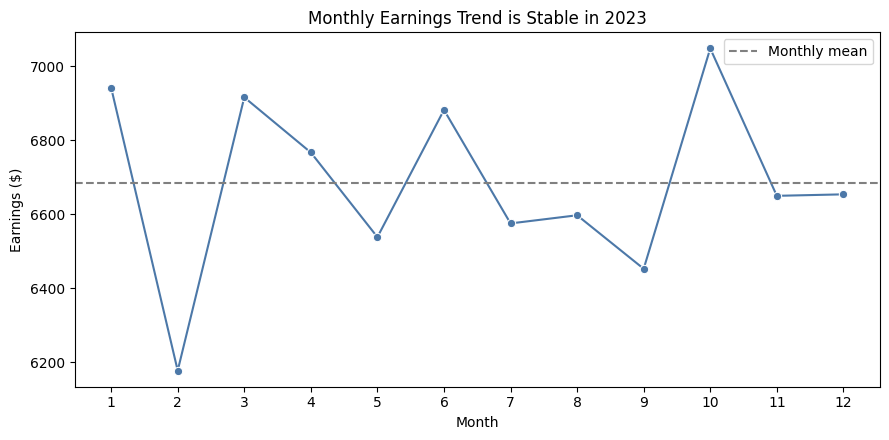

In [517]:
plot_monthly_earnings_trend(data)

The trend is stable around \$6000-\$7000 per month, huge decline in February because it has the fewest days (28 days)



---


- Weekday Pattern

In [518]:
def plot_weekday_pattern(data):
    """
      Line plot
      Average daily earnings for each day of the week (Mon-Sun)
      Shows whether weekends is different from weekdays.
    """
    dated = data.dropna(subset=["Transaction Date"])
    daily = (dated.groupby("Transaction Date")
             .agg(earnings=("Total Spent", "sum"), transactions=("Transaction ID", "count"))
             .reset_index())
    daily["Weekday No"] = daily["Transaction Date"].dt.dayofweek
    daily["Day Type"] = np.where(daily["Weekday No"] >= 5, "Weekend", "Weekday")
    names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.axvspan(4.5, 6.5, color="orange", alpha=0.12, label="Weekend")
    sns.lineplot(data=daily, x="Weekday No", y="earnings", marker="o", errorbar=("ci", 95),
                 color="#4C78A8", ax=ax, label="Mean daily earnings (95% CI)")
    ax.axhline(daily["earnings"].mean(), ls="--", color="grey", label="Overall daily mean")
    ax.set(title="The Earnings During Weekdays and Weekends are Similar", xlabel="Day of week",
           ylabel="Earnings per day ($)", xticks=range(7), xticklabels=names)
    ax.legend(loc="lower right")
    return save_plot(fig, "Weekday Pattern.png")

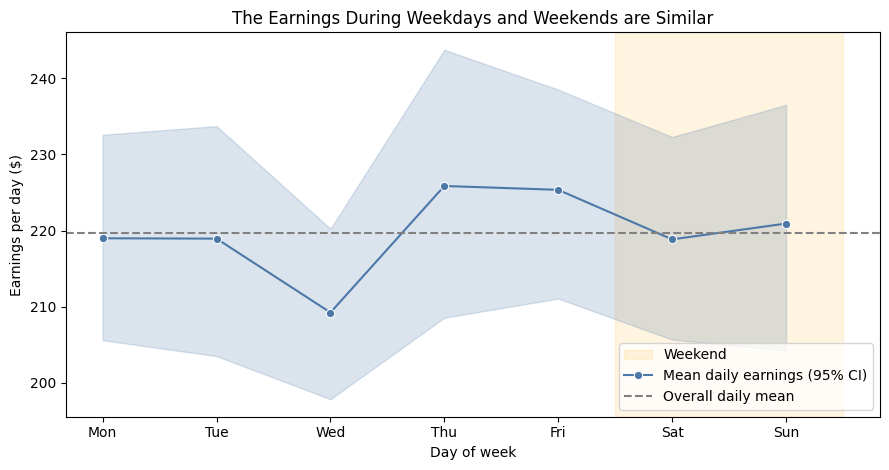

In [519]:
plot_weekday_pattern(data)

There are no big differences in earnings between weekends and weekdays, the mean for each day is around \$200-\$215 per day

## **Categorical Plots**
- Item Popularity

because I wanna see which item is the most bought by customers
- Payment by Location

because I wanna see if location affects the payment method



---

- Item Popularity

In [520]:
def plot_item_popularity(data):
    """
      Bar plot
      Number of transactions for each item.
    """
    data = data[data["Item"] != "Unknown"].copy()
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.countplot(data=data, x="Item", hue="Item", legend=False,
                  order=data["Item"].value_counts().index, ax=ax)
    ax.set(title="Customers Buy About The Same Amount of Item Each Type", ylabel="Transactions")
    ax.tick_params(axis="x", rotation=45)
    return save_plot(fig, "Item Popularity.png")

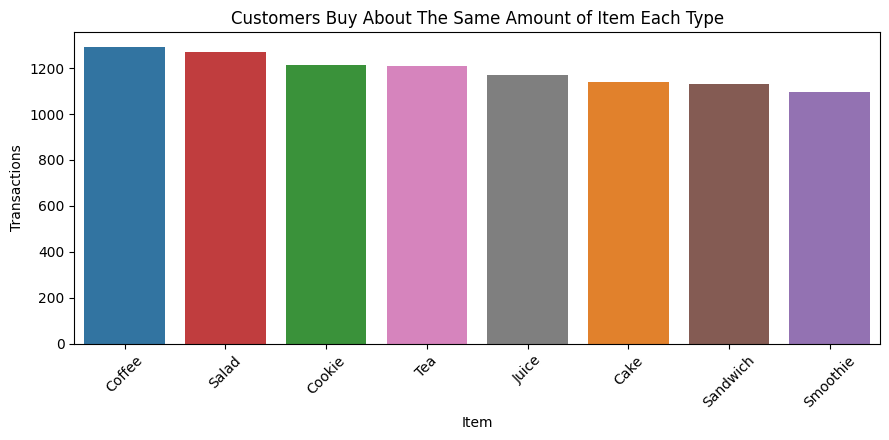

In [521]:
plot_item_popularity(data)

All 8 items sell about equally often, at 1,100 to 1,300 transactions each.







---


- Payment by Location

In [522]:
def plot_payment_by_location(data) -> str:
    """CATEGORICAL (grouped bar plot): transactions by payment method, split by
    location (the 'Unknown' categories are shown, not hidden)."""
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.countplot(data=data, x="Payment Method", hue="Location",
                  order=data["Payment Method"].value_counts().index, ax=ax)
    ax.set(title="Payment Method and Location doesn't make a pattern", ylabel="Transactions")
    ax.legend(title="Location")
    return save_plot(fig, "Payment By Location.png")

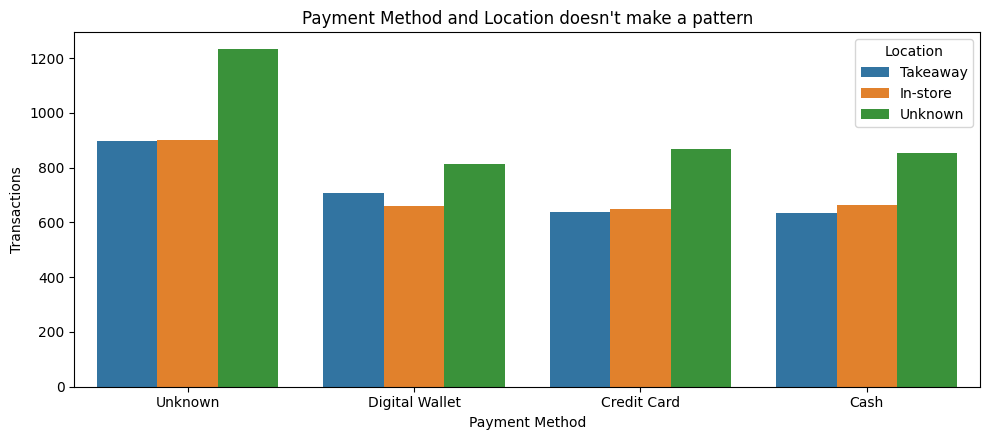

In [523]:
plot_payment_by_location(data)

Location and payment method don't change spending.
In-store and Takeaway are split 50/50, and Cash, Card and Digital Wallet are each about a third.

We can see that "Unknown" dominates the data, so the data should be fixed

## **Statistical Plot**
- Total Spent Distribution

because the skewness of "Total Spent" is 0.821406... I wanna see the "Total Spent" distribution in a plot

In [524]:
def plot_total_spent_distribution(data):
    """
       Histogram + KDE
       Distribution of Total Spent with mean and median markers
       To show its right skew.
    """
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.histplot(data["Total Spent"], bins=20, kde=True, color="#F58518", ax=ax)
    ax.axvline(data["Total Spent"].mean(), color="black", ls="--",
               label=f"Mean = {data['Total Spent'].mean():.2f}")
    ax.axvline(data["Total Spent"].median(), color="green", ls=":",
               label=f"Median = {data['Total Spent'].median():.2f}")
    ax.set(title="Most Transactions are Small Total Spent", xlabel="Total Spent ($)")
    ax.legend()
    return save_plot(fig, "Total Spent Distribution.png")

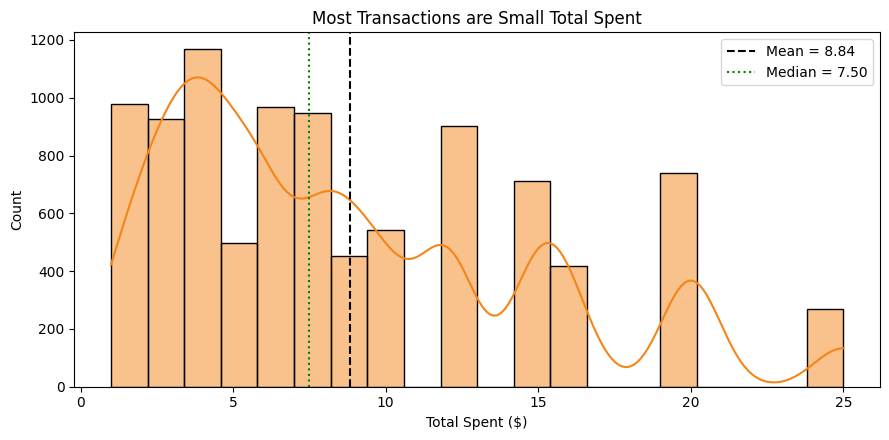

In [525]:
plot_total_spent_distribution(data)

Right-skewed: Most transactions are small, and a minority are much larger and pull the tail to the right.


---



### **Prediction**
Trying to predict if low-value items (Coffee, Cookie, and Tea) price rises by $0.5

In [526]:
def price_increase_scenario(data, increases):
    """
      What-if analysis
      Monthly earnings after raising item prices.
    """
    unknown = set(increases) - set(data["Item"].unique())
    if unknown:
        raise ValueError(f"Items not found in data: {sorted(unknown)}")

    data = data.dropna(subset=["Transaction Date"]).copy()

    bump = data["Item"].map(increases).fillna(0.0)

    data["new_total"] = (
        data["Total Spent"] + data["Quantity"] * bump
    )

    monthly = (
        data.groupby("Month")
        .agg(
            current=("Total Spent", "sum"),
            new=("new_total", "sum")
        )
    )

    monthly.loc["Year"] = monthly.sum()

    monthly["gain"] = monthly["new"] - monthly["current"]
    monthly["gain_pct"] = (
        monthly["gain"] / monthly["current"] * 100
    )

    return monthly.round(2)

In [527]:
increases = {"Coffee": 0.5, "Tea": 0.5, "Cookie": 0.5}
price_increase_scenario(data, increases)

,current,new,gain,gain_pct
Month,,,,
1,6942.0,7389.5,447.5,6.45
2,6178.0,6598.0,420.0,6.8
3,6916.0,7392.0,476.0,6.88
4,6767.0,7169.5,402.5,5.95
5,6538.5,6951.5,413.0,6.32
6,6882.0,7329.0,447.0,6.5
7,6575.5,7041.0,465.5,7.08
8,6597.5,7057.5,460.0,6.97
9,6453.0,6892.5,439.5,6.81
